# Entrega 2 · Propuesta metodológica: pronóstico de rendimiento por cuartel en kiwi Hayward

**Grupo 36 · Diplomado en Data Science 2026 · PUC**

Este notebook reúne todo el análisis que respalda la presentación de la Entrega 2. Parte de los archivos originales de `Datos kiwi` (los mismos de la Entrega 1) y genera las cifras y los datos de los gráficos de la presentación.

| Sección | Qué responde | Diapositivas |
|---|---|---|
| 1. Panel cuartel-temporada | ¿Partimos de los mismos datos que la Entrega 1? | 2–3 |
| 2. Hallazgos que condicionan la metodología | ¿La canopia antes de cosecha sirve para pronosticar? | 3 |
| 3. Validación temporal preliminar | ¿Qué modelo le gana al promedio histórico? | 6, 11 |
| 4. Robustez | ¿El resultado se sostiene año a año, a ciegas y frente al ruido? | 8–11 |
| 5. Punto de equilibrio | ¿De dónde sale el umbral de 19,1 t/ha? | 2, 5, 7 |

**Cómo se usa.** Ejecutar todas las celdas en orden (*Run All*). Los resultados quedan en `salidas/`, y la presentación se construye desde ahí con `node build_deck.js` en la carpeta `presentacion`.

> No es el modelo definitivo: es la evidencia preliminar para justificar las decisiones metodológicas antes de implementar.

## 0. Configuración

In [1]:
import json
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from IPython.display import display
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import RidgeCV
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error, mean_squared_error

warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
plt.rcParams['figure.figsize'] = (9, 5)


def buscar_carpeta(nombre):
    """Busca la carpeta subiendo desde la ubicacion del notebook (funciona en cualquier equipo)."""
    for base in [Path.cwd(), *Path.cwd().parents]:
        if (base / nombre).is_dir():
            return base / nombre
    raise FileNotFoundError(f'No se encontro la carpeta {nombre!r} sobre {Path.cwd()}')


CARPETA_DATOS = buscar_carpeta('Datos kiwi')
CARPETA_SALIDA = Path.cwd() / 'salidas'
CARPETA_SALIDA.mkdir(exist_ok=True)

# Dias de temporada (1 = 1 de mayo). 154 = 1 de octubre, inicio de brotacion.
DIA_INICIO_CRECIMIENTO = 154
CORTES = {'dic': 245, 'ene': 276, 'feb': 304}   # 31 dic, 31 ene, 28 feb
ANIOS_TEST = [2022, 2023, 2024, 2025, 2026]
SEMILLA = 36

print('Datos:', CARPETA_DATOS)
print('Salidas:', CARPETA_SALIDA)

Datos: c:\Users\Jason Leon\Desktop\MaterialEstudioDS\Entregas Evaluaciones\Datos kiwi
Salidas: c:\Users\Jason Leon\Desktop\MaterialEstudioDS\Entregas Evaluaciones\Segunda entrega\analisis\salidas


## 1. Panel cuartel-temporada

Unidad de análisis: **cuartel × año de cosecha**. La temporada agrícola va del 1 de mayo al 30 de abril; la cosecha del año *Y* corresponde a la temporada (*Y*−1)–*Y*.

Las métricas de canopia se calculan **solo hasta una fecha de corte previa a la cosecha** para evitar fuga de información: la temporada completa incluye marzo y abril, que son cosecha y postcosecha.

In [2]:
def leer_productivos():
    crudo = pd.read_excel(CARPETA_DATOS / 'COMPARATIVO PRODUCTIVOS.xlsx', header=None)
    anios = crudo.iloc[3, 2:10].astype(int).tolist()
    filas = []
    for i in range(4, len(crudo)):
        cuartel = crudo.iloc[i, 0]
        if pd.isna(cuartel) or str(cuartel).startswith('TOTAL'):
            continue
        has = float(crudo.iloc[i, 1])
        bins = crudo.iloc[i + 1, 2:10].tolist()
        kg = crudo.iloc[i + 2, 2:10].tolist()
        for anio, b, k in zip(anios, bins, kg):
            filas.append({'cuartel': str(cuartel).replace(' Y ', '_'), 'has': has, 'anio': anio,
                          'bins': b, 'kg_cuartel': k, 'ton_ha': k / has / 1000})
    return pd.DataFrame(filas)


def leer_canopia():
    canopia = pd.read_excel(
        CARPETA_DATOS / 'CONSOLIDADO_curvas_temporada_planet.xlsx', sheet_name='Datos_diarios',
        usecols=['cuartel', 'fecha', 'temporada', 'dia_temporada', 'cb_invertido_suavizado'],
    )
    canopia['cuartel'] = canopia['cuartel'].str.replace('c', '', regex=False)
    canopia['anio'] = canopia['temporada'].str[-4:].astype(int)
    return canopia


def metricas_canopia(canopia):
    """Metricas por cuartel-anio: temporada completa (como la Entrega 1) y hasta cada corte."""
    grupos = canopia.groupby(['cuartel', 'anio'])
    salida = grupos['cb_invertido_suavizado'].mean().rename('cnp_media_completa').to_frame()
    for nombre, dia in CORTES.items():
        # Desde el 1 de mayo hasta el corte: incluye la senal invernal, que es la mas informativa.
        acumulada = canopia[canopia['dia_temporada'] <= dia]
        salida[f'cnp_acum_{nombre}'] = acumulada.groupby(['cuartel', 'anio'])['cb_invertido_suavizado'].mean()
        ventana = canopia[canopia['dia_temporada'].between(DIA_INICIO_CRECIMIENTO, dia)]
        g = ventana.groupby(['cuartel', 'anio'])['cb_invertido_suavizado']
        salida[f'cnp_media_{nombre}'] = g.mean()
        salida[f'cnp_max_{nombre}'] = g.max()
        # Pendiente de crecimiento de la canopia en la ventana (unidades por dia).
        salida[f'cnp_pend_{nombre}'] = ventana.groupby(['cuartel', 'anio'])[
            ['dia_temporada', 'cb_invertido_suavizado']
        ].apply(lambda d: np.polyfit(d['dia_temporada'], d['cb_invertido_suavizado'], 1)[0])
    return salida.reset_index()


def leer_clima():
    eto = pd.read_excel(CARPETA_DATOS / 'datos_eto.xlsx', sheet_name='Calculos_diarios')
    eto['fecha'] = pd.to_datetime(eto['fecha'])
    eto['anio'] = eto['temporada'].str[-4:].astype(int)
    eto['DPV_kPa'] = eto['es_kPa'] - eto['ea_kPa']
    return eto


def metricas_clima(eto, dia_corte=CORTES['ene']):
    """Acumulados por temporada; solo temporadas con invierno completo (cosecha 2023-2026)."""
    eto = eto[eto['anio'].between(2023, 2026)]
    invierno = eto[eto['fecha'].dt.month.isin([5, 6, 7, 8])]
    crecimiento = eto[eto['dia_temporada'].between(DIA_INICIO_CRECIMIENTO - 31, dia_corte)]
    clima = pd.DataFrame({
        'horas_frio': invierno.groupby('anio')['Tmin_C'].apply(lambda t: (t <= 7.2).sum() * 24),
        'gdd_b7': crecimiento.groupby('anio')['Tmean_C'].apply(lambda t: np.maximum(t - 7, 0).sum()),
        'gdd_b10': crecimiento.groupby('anio')['Tmean_C'].apply(lambda t: np.maximum(t - 10, 0).sum()),
        'precip_mm': eto[eto['dia_temporada'] <= dia_corte].groupby('anio')['precip_mm'].sum(),
        'dpv_kpa': crecimiento.groupby('anio')['DPV_kPa'].mean(),
    })
    return clima.reset_index()


def construir_panel():
    productivos = leer_productivos()
    canopia = metricas_canopia(leer_canopia())
    clima = metricas_clima(leer_clima())
    panel = (productivos
             .merge(canopia, on=['cuartel', 'anio'], how='left')
             .merge(clima, on='anio', how='left'))
    return panel.sort_values(['cuartel', 'anio']).reset_index(drop=True)


panel = construir_panel()
panel.to_csv(CARPETA_SALIDA / 'panel_integrado.csv', index=False)
print('Panel:', panel.shape, '| observaciones con canopia:', panel['cnp_acum_ene'].notna().sum())
display(panel.groupby('anio')['ton_ha'].agg(['count', 'mean']).round(1).T)

Panel: (112, 24) | observaciones con canopia: 77


anio,2019,2020,2021,2022,2023,2024,2025,2026
count,14.0,14.0,14.0,14.0,14.0,14.0,14.0,14.0
mean,34.3,32.1,35.9,27.1,26.8,42.6,34.8,42.0


### 1.1 Control de coherencia con la Entrega 1

La Entrega 1 leía un panel ya consolidado. Aquí el panel se reconstruye desde los archivos originales, así que primero se comprueba que entrega **las mismas cifras** que se publicaron en la Entrega 1. Si alguna no coincide, la celda se detiene.

In [3]:
y = panel['ton_ha']
cnp = panel['cnp_media_completa'].dropna()
medias_cuartel = panel.groupby('cuartel')['ton_ha'].mean()
medias_anio = panel.groupby('anio')['ton_ha'].mean()

control = pd.DataFrame([
    ('Observaciones cuartel-temporada', 112, len(panel)),
    ('Media ton/ha', 34.448, y.mean()),
    ('Mediana ton/ha', 33.817, y.median()),
    ('Desviación ton/ha', 10.138, y.std()),
    ('Asimetría ton/ha', 0.407, y.skew()),
    ('Máximo ton/ha (cuartel 10, 2026)', 67.722, y.max()),
    ('Media temporada 2023', 26.8, medias_anio[2023]),
    ('Media temporada 2024', 42.6, medias_anio[2024]),
    ('Media mínima por cuartel', 23.1, medias_cuartel.min()),
    ('Media máxima por cuartel', 44.8, medias_cuartel.max()),
    ('Observaciones con canopia', 77, len(cnp)),
    ('Canopia media de temporada', 0.544, cnp.mean()),
    ('r canopia temporada vs ton/ha', 0.67, panel[['cnp_media_completa', 'ton_ha']].corr().iloc[0, 1]),
    ('P10 rendimiento (escenario pesimista)', 21.91, y.quantile(0.10)),
    ('P50 rendimiento (escenario intermedio)', 33.82, y.quantile(0.50)),
    ('P90 rendimiento (escenario optimista)', 47.03, y.quantile(0.90)),
], columns=['indicador', 'entrega_1', 'entrega_2'])
decimales = control['entrega_1'].astype(str).str.split('.').str[1].str.len().fillna(0).astype(int)
control['entrega_2'] = [round(v, d) for v, d in zip(control['entrega_2'], decimales)]
control['coincide'] = np.isclose(control['entrega_1'], control['entrega_2'])
display(control)
assert control['coincide'].all(), 'El panel no reproduce la Entrega 1'
print('El panel reproduce las cifras publicadas en la Entrega 1.')

,indicador,entrega_1,entrega_2,coincide
0,Observaciones cuartel-temporada,112.000,112.000,True
1,Media ton/ha,34.448,34.448,True
2,Mediana ton/ha,33.817,33.817,True
3,Desviación ton/ha,10.138,10.138,True
4,Asimetría ton/ha,0.407,0.407,True
5,"Máximo ton/ha (cuartel 10, 2026)",67.722,67.722,True
6,Media temporada 2023,26.800,26.800,True
7,Media temporada 2024,42.600,42.600,True
8,Media mínima por cuartel,23.100,23.100,True
9,Media máxima por cuartel,44.800,44.800,True


El panel reproduce las cifras publicadas en la Entrega 1.


## 2. Hallazgos que condicionan la metodología

En la Entrega 1 la canopia de **toda la temporada** se correlacionaba 0,67 con el rendimiento, pero ese promedio incluye los meses de cosecha: no está disponible cuando hay que planificar. La pregunta es si la señal **hasta una fecha de corte** conserva esa información.

,r,n
cnp_media_completa,0.672,77.0
cnp_acum_dic,0.640,77.0
cnp_acum_ene,0.659,77.0
cnp_acum_feb,0.667,77.0


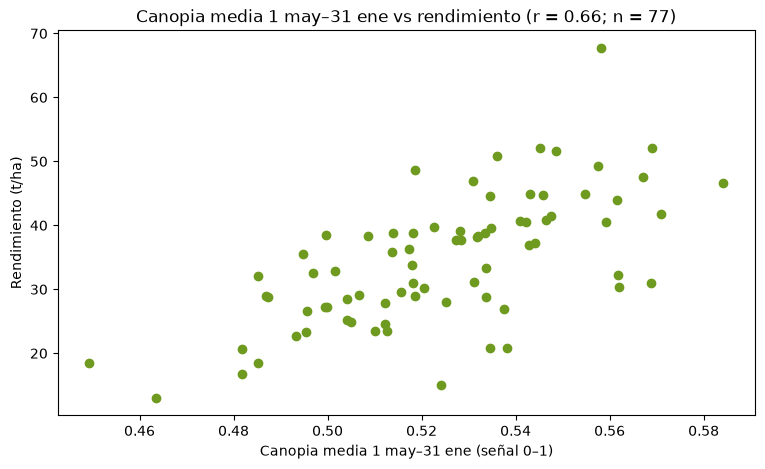

In [4]:
correlaciones_corte = pd.DataFrame({
    var: {'r': panel[[var, 'ton_ha']].dropna().corr().iloc[0, 1], 'n': panel[var].notna().sum()}
    for var in ['cnp_media_completa', 'cnp_acum_dic', 'cnp_acum_ene', 'cnp_acum_feb']
}).T.round(3)
display(correlaciones_corte)

# Datos del grafico de dispersion de la diapositiva 3 (canopia al 31 de enero).
dispersion = panel.dropna(subset=['cnp_acum_ene'])
(CARPETA_SALIDA / 'scatter_ene.json').write_text(json.dumps({
    'x': [round(v, 4) for v in dispersion['cnp_acum_ene']],
    'y': [round(v, 2) for v in dispersion['ton_ha']],
}), encoding='utf-8')

plt.scatter(dispersion['cnp_acum_ene'], dispersion['ton_ha'], color='#6E9A1F')
plt.title(f"Canopia media 1 may–31 ene vs rendimiento (r = {correlaciones_corte.loc['cnp_acum_ene', 'r']:.2f}; n = {len(dispersion)})")
plt.xlabel('Canopia media 1 may–31 ene (señal 0–1)')
plt.ylabel('Rendimiento (t/ha)')
plt.show()

**Lectura.** Al cortar al 31 de enero la correlación pasa de 0,67 a 0,66: se conserva casi toda la señal y ya está disponible dos a tres meses antes de la cosecha. Con solo 77 observaciones y cada cuartel manteniendo su propio nivel entre años, el modelo debe tener **pocos predictores** y un **efecto por cuartel**. El clima solo cubre cuatro temporadas completas, así que queda fuera del modelo principal.

## 3. Validación temporal preliminar

Ventana expansiva: para cada año de prueba *Y* se entrena con las cosechas anteriores a *Y* y se predice *Y*. Nunca se usa el futuro para predecir el pasado.

- **Baselines:** promedio histórico del cuartel (la práctica actual) y temporada anterior.
- **Modelos:** Ridge con efecto fijo de cuartel, modelo mixto con intercepto aleatorio por cuartel, Random Forest y Gradient Boosting.
- **Variantes de canopia:** hasta el 31 de diciembre, 31 de enero y 28 de febrero, la media de la ventana de crecimiento a enero y la temporada completa (solo como referencia, porque tiene fuga).

In [5]:
def predecir_baselines(train, test):
    media_cuartel = train.groupby('cuartel')['ton_ha'].mean()
    ultimo = train.sort_values('anio').groupby('cuartel')['ton_ha'].last()
    return {
        'B0 Promedio historico del cuartel': test['cuartel'].map(media_cuartel).values,
        'B1 Temporada anterior': test['cuartel'].map(ultimo).values,
    }


def matriz(datos, cols, cuarteles):
    x = datos[cols].copy()
    for c in cuarteles[1:]:
        x[f'q_{c}'] = (datos['cuartel'] == c).astype(float)
    return x


def predecir_modelos(train, test, var_cnp):
    cuarteles = sorted(train['cuartel'].unique())
    predicciones = {}

    # Ridge con efecto fijo de cuartel: lineal e interpretable, regularizado por n pequeno.
    cols = [var_cnp]
    xtr, xte = matriz(train, cols, cuarteles), matriz(test, cols, cuarteles)
    media, desv = xtr[cols].mean(), xtr[cols].std()
    xtr[cols], xte[cols] = (xtr[cols] - media) / desv, (xte[cols] - media) / desv
    ridge = RidgeCV(alphas=np.logspace(-2, 3, 30)).fit(xtr, train['ton_ha'])
    predicciones['M1 Ridge (canopia + cuartel)'] = ridge.predict(xte)

    # Modelo mixto: intercepto aleatorio por cuartel (comparte informacion entre cuarteles).
    mixto = smf.mixedlm(f'ton_ha ~ {var_cnp}', train, groups=train['cuartel']).fit(reml=True)
    efectos = {k: v.iloc[0] for k, v in mixto.random_effects.items()}
    predicciones['M2 Modelo mixto (cuartel aleatorio)'] = (
        mixto.predict(test).values + test['cuartel'].map(efectos).fillna(0).values
    )

    # Arboles: el cuartel entra como su promedio historico (target encoding solo con train).
    media_cuartel = train.groupby('cuartel')['ton_ha'].mean()
    cols_arbol = [var_cnp, 'has']
    xtr_a = train[cols_arbol].assign(media_cuartel=train['cuartel'].map(media_cuartel))
    xte_a = test[cols_arbol].assign(media_cuartel=test['cuartel'].map(media_cuartel))
    rf = RandomForestRegressor(n_estimators=500, min_samples_leaf=3, random_state=SEMILLA)
    predicciones['M3 Random Forest'] = rf.fit(xtr_a, train['ton_ha']).predict(xte_a)
    gb = GradientBoostingRegressor(n_estimators=200, max_depth=2, learning_rate=0.05,
                                   subsample=0.8, random_state=SEMILLA)
    predicciones['M4 Gradient Boosting'] = gb.fit(xtr_a, train['ton_ha']).predict(xte_a)
    return predicciones


def validacion_temporal(panel, var_cnp):
    datos = panel.dropna(subset=[var_cnp])
    filas = []
    for anio in ANIOS_TEST:
        train, test = datos[datos['anio'] < anio], datos[datos['anio'] == anio]
        preds = {**predecir_baselines(train, test), **predecir_modelos(train, test, var_cnp)}
        for modelo, pred in preds.items():
            for (_, fila), p in zip(test.iterrows(), pred):
                filas.append({'anio': anio, 'cuartel': fila['cuartel'], 'has': fila['has'],
                              'modelo': modelo, 'real': fila['ton_ha'], 'pred': p})
    return pd.DataFrame(filas)


def resumir(pred):
    def metricas(g):
        kg_real = (g['real'] * g['has']).groupby(g['anio']).sum()
        kg_pred = (g['pred'] * g['has']).groupby(g['anio']).sum()
        return pd.Series({
            'MAPE_%': 100 * mean_absolute_percentage_error(g['real'], g['pred']),
            'RMSE': np.sqrt(mean_squared_error(g['real'], g['pred'])),
            'MAE': mean_absolute_error(g['real'], g['pred']),
            'Error_huerto_%': 100 * ((kg_pred - kg_real).abs() / kg_real).mean(),
        })
    return pred.groupby('modelo').apply(metricas).round(2).sort_values('MAPE_%')

In [6]:
VARIANTES = ['cnp_acum_dic', 'cnp_acum_ene', 'cnp_acum_feb', 'cnp_media_ene', 'cnp_media_completa']
predicciones, tablas = {}, []
for var in VARIANTES:
    pred = validacion_temporal(panel, var)
    pred.to_csv(CARPETA_SALIDA / f'predicciones_{var}.csv', index=False)
    predicciones[var] = pred
    tabla = resumir(pred)
    tabla.insert(0, 'variable_canopia', var)
    tablas.append(tabla)
resultados = pd.concat(tablas)
resultados.to_csv(CARPETA_SALIDA / 'resultados_validacion.csv')

print('Variante principal: canopia hasta el 31 de enero')
display(resultados[resultados['variable_canopia'] == 'cnp_acum_ene'])
print('Error del total del huerto (%) del modelo mixto según fecha de corte')
display(resultados[resultados.index.str.startswith('M2')].set_index('variable_canopia')[['Error_huerto_%', 'MAE']])

Variante principal: canopia hasta el 31 de enero


,variable_canopia,MAPE_%,RMSE,MAE,Error_huerto_%
modelo,,,,,
M2 Modelo mixto (cuartel aleatorio),cnp_acum_ene,19.25,7.95,6.24,9.60
M1 Ridge (canopia + cuartel),cnp_acum_ene,19.93,8.03,6.34,10.51
M4 Gradient Boosting,cnp_acum_ene,21.49,8.91,6.84,11.77
M3 Random Forest,cnp_acum_ene,21.89,8.64,6.87,15.40
B0 Promedio historico del cuartel,cnp_acum_ene,22.75,9.50,7.38,17.35
B1 Temporada anterior,cnp_acum_ene,24.55,10.10,8.05,19.12


Error del total del huerto (%) del modelo mixto según fecha de corte


,Error_huerto_%,MAE
variable_canopia,,
cnp_acum_dic,10.30,6.42
cnp_acum_ene,9.60,6.24
cnp_acum_feb,9.73,6.31
cnp_media_ene,14.69,7.15
cnp_media_completa,10.73,6.39


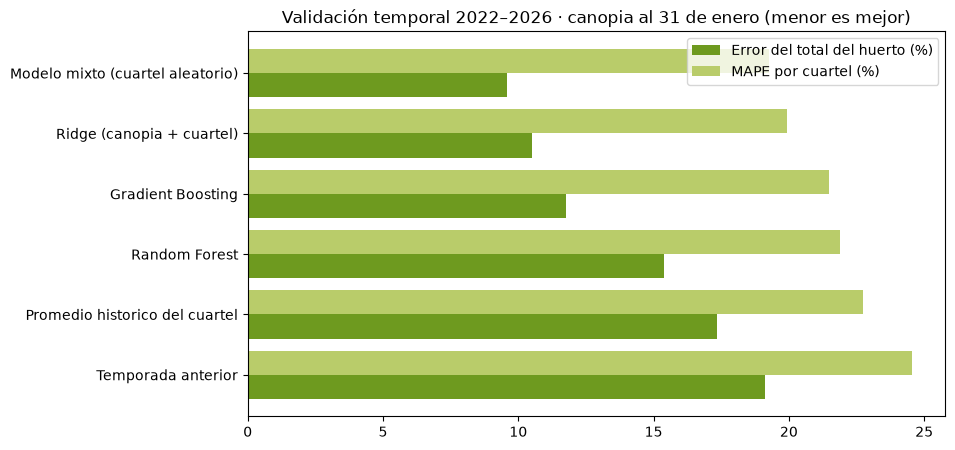

In [7]:
principal = resultados[resultados['variable_canopia'] == 'cnp_acum_ene'].sort_values('Error_huerto_%', ascending=False)
etiquetas = [m.split(' ', 1)[1] for m in principal.index]
pos = np.arange(len(principal))
plt.barh(pos - 0.2, principal['Error_huerto_%'], height=0.4, color='#6E9A1F', label='Error del total del huerto (%)')
plt.barh(pos + 0.2, principal['MAPE_%'], height=0.4, color='#B9CC6A', label='MAPE por cuartel (%)')
plt.yticks(pos, etiquetas)
plt.title('Validación temporal 2022–2026 · canopia al 31 de enero (menor es mejor)')
plt.legend()
plt.show()

**Lectura.** Con la canopia al 31 de enero, el modelo mixto baja el error del total del huerto de 17,4 % (promedio histórico) a 9,6 %, y Ridge queda casi igual. Los árboles rinden peor: con 77 casos no aportan no linealidad que compense su menor interpretabilidad. En diciembre el modelo ya supera al baseline (10,3 %) y febrero no mejora a enero (9,7 %), por eso el corte propuesto es el 31 de enero.

## 4. Robustez del resultado preliminar

Cuatro preguntas que haría un evaluador:

1. ¿El modelo le gana al baseline **todos los años** o solo en promedio?
2. ¿El baseline es **justo**? La práctica real usa toda la historia, incluida 2019 y los cuarteles sin señal de canopia.
3. ¿El resultado está inflado por haber elegido la variante y el modelo con los mismos años con que se reporta el error (**sesgo de selección**)? Se vuelve a elegir usando solo 2022–2025 y se evalúa la elección una sola vez en 2026.
4. ¿La mejora es mayor que el **ruido de muestreo**? Bootstrap pareado remuestreando cuarteles completos.

In [8]:
MODELOS = ['M1 Ridge (canopia + cuartel)', 'M2 Modelo mixto (cuartel aleatorio)',
           'M3 Random Forest', 'M4 Gradient Boosting']
BASELINE = 'B0 Promedio historico del cuartel'
PRINCIPAL = ('cnp_acum_ene', 'M2 Modelo mixto (cuartel aleatorio)')
ANIOS_SELECCION = [2022, 2023, 2024, 2025]
ANIO_CIEGO = 2026
N_BOOT = 10_000

# Mismas predicciones fuera de muestra de la seccion 3, leidas como quedaron guardadas.
pred_todas = pd.concat(
    [pd.read_csv(CARPETA_SALIDA / f'predicciones_{v}.csv').assign(variante=v) for v in VARIANTES],
    ignore_index=True,
)


def error_huerto(g):
    """Promedio por anio de |kg totales predichos - kg totales reales| / kg totales reales (en %)."""
    kg_real = (g['real'] * g['has']).groupby(g['anio']).sum()
    kg_pred = (g['pred'] * g['has']).groupby(g['anio']).sum()
    return 100 * ((kg_pred - kg_real).abs() / kg_real).mean()


def metricas(g):
    return pd.Series({
        'MAE': (g['pred'] - g['real']).abs().mean(),
        'MAPE_%': 100 * ((g['pred'] - g['real']).abs() / g['real']).mean(),
        'Error_huerto_%': error_huerto(g),
        'n': len(g),
    })


def por_anio(pred):
    var, modelo = PRINCIPAL
    sub = pred[(pred['variante'] == var) & pred['modelo'].isin([BASELINE, modelo])]
    # Se agrupa por una copia del anio: pandas excluye las claves de agrupacion del grupo.
    tabla = (sub.assign(anio_grupo=sub['anio'])
             .groupby(['anio_grupo', 'modelo']).apply(metricas).unstack('modelo'))
    tabla.columns = [f'{m}|{c}' for m, c in tabla.columns]
    for m in ['MAE', 'MAPE_%', 'Error_huerto_%']:
        tabla[f'gana_{m}'] = tabla[f'{m}|{modelo}'] < tabla[f'{m}|{BASELINE}']
    return tabla


def baseline_justo(pred):
    var, modelo = PRINCIPAL
    test = pred[(pred['variante'] == var) & (pred['modelo'] == BASELINE)].copy()
    test['pred'] = [
        panel[(panel['anio'] < a) & (panel['cuartel'] == str(c))]['ton_ha'].mean()
        for a, c in zip(test['anio'], test['cuartel'])
    ]
    test['modelo'] = 'B0b Promedio historico (toda la historia)'
    base = pred[(pred['variante'] == var) & pred['modelo'].isin([BASELINE, modelo])]
    return pd.concat([base, test]).groupby('modelo').apply(metricas)


def seleccion_ciega(pred):
    candidatos = pred[pred['modelo'].isin(MODELOS)]
    sel = (candidatos[candidatos['anio'].isin(ANIOS_SELECCION)]
           .groupby(['variante', 'modelo']).apply(metricas).sort_values('MAE'))
    var, modelo = sel.index[0]
    ciego = pred[(pred['anio'] == ANIO_CIEGO) & (pred['variante'] == var)
                 & pred['modelo'].isin([BASELINE, modelo])]
    return sel, (var, modelo), ciego.groupby('modelo').apply(metricas)


def bootstrap(pred):
    var, modelo = PRINCIPAL
    sub = pred[pred['variante'] == var]
    ancho = sub.pivot_table(index=['cuartel', 'anio'], columns='modelo', values='pred')
    real = sub.drop_duplicates(['cuartel', 'anio']).set_index(['cuartel', 'anio'])['real']
    err_b = (ancho[BASELINE] - real).abs()
    err_m = (ancho[modelo] - real).abs()
    cuarteles = np.array(sorted(real.index.get_level_values('cuartel').unique()))
    grupos = {c: (err_b.xs(c, level='cuartel').values, err_m.xs(c, level='cuartel').values)
              for c in cuarteles}
    rng = np.random.default_rng(SEMILLA)
    difs = np.empty(N_BOOT)
    for i in range(N_BOOT):
        elegidos = rng.choice(cuarteles, size=len(cuarteles), replace=True)
        b = np.concatenate([grupos[c][0] for c in elegidos])
        m = np.concatenate([grupos[c][1] for c in elegidos])
        difs[i] = b.mean() - m.mean()
    observada = err_b.mean() - err_m.mean()
    resumen = {
        'mae_baseline': round(float(err_b.mean()), 3),
        'mae_modelo': round(float(err_m.mean()), 3),
        'diferencia': round(float(observada), 3),
        'reduccion_%': round(float(100 * observada / err_b.mean()), 1),
        'ic95': [round(float(np.percentile(difs, 2.5)), 3), round(float(np.percentile(difs, 97.5)), 3)],
        'prob_mejora': round(float((difs > 0).mean()), 4),
        'n_cuarteles': int(len(cuarteles)),
        'n_predicciones': int(len(real)),
    }
    return resumen, difs

In [9]:
t_anio = por_anio(pred_todas)
t_justo = baseline_justo(pred_todas)
t_sel, elegido, t_ciego = seleccion_ciega(pred_todas)
t_boot, difs_boot = bootstrap(pred_todas)
t_corr = {var: {'r': round(float(panel[[var, 'ton_ha']].dropna().corr().iloc[0, 1]), 3),
                'n': int(panel[var].notna().sum())}
          for var in ['cnp_media_completa', 'cnp_acum_ene']}

print('1. Error del total del huerto (%) por año')
display(t_anio[[c for c in t_anio.columns if c.startswith('Error_huerto') or c == 'gana_Error_huerto_%']].round(1))
print('2. Baseline con toda la historia (desde 2019)')
display(t_justo.round(2))
print('3. Selección con 2022–2025 → elegido:', elegido)
display(t_sel.head(6).round(2))
print('   Prueba ciega 2026')
display(t_ciego.round(2))
print('4. Bootstrap por cuartel:', t_boot)

resumen_robustez = {
    'por_anio': t_anio.round(3).reset_index().to_dict(orient='records'),
    'baseline_justo': t_justo.round(3).reset_index().to_dict(orient='records'),
    'seleccion_top': t_sel.head(6).round(3).reset_index().to_dict(orient='records'),
    'elegido_ciego': list(elegido),
    'ciego_2026': t_ciego.round(3).reset_index().to_dict(orient='records'),
    'bootstrap': t_boot,
    'correlaciones': t_corr,
}
(CARPETA_SALIDA / 'robustez.json').write_text(
    json.dumps(resumen_robustez, indent=2, ensure_ascii=False, default=str), encoding='utf-8')

1. Error del total del huerto (%) por año


,Error_huerto_%|B0 Promedio historico del cuartel,Error_huerto_%|M2 Modelo mixto (cuartel aleatorio),gana_Error_huerto_%
anio_grupo,,,
2022,18.9,1.3,True
2023,16.0,9.5,True
2024,24.5,19.8,True
2025,5.7,10.5,False
2026,21.6,7.0,True


2. Baseline con toda la historia (desde 2019)


,MAE,MAPE_%,Error_huerto_%,n
modelo,,,,
B0 Promedio historico del cuartel,7.38,22.75,17.35,55.0
B0b Promedio historico (toda la historia),7.44,24.34,16.82,55.0
M2 Modelo mixto (cuartel aleatorio),6.24,19.25,9.60,55.0


3. Selección con 2022–2025 → elegido: ('cnp_acum_ene', 'M2 Modelo mixto (cuartel aleatorio)')


MAE  MAPE_%  Error_huerto_%     n
variante           modelo                                                                 
cnp_acum_ene       M2 Modelo mixto (cuartel aleatorio)  5.93   19.76           10.25  44.0
                   M1 Ridge (canopia + cuartel)         6.00   20.45           11.34  44.0
cnp_acum_feb       M2 Modelo mixto (cuartel aleatorio)  6.00   19.81           10.52  44.0
cnp_media_completa M2 Modelo mixto (cuartel aleatorio)  6.02   19.11           11.12  44.0
                   M1 Ridge (canopia + cuartel)         6.04   19.95           10.85  44.0
cnp_acum_feb       M1 Ridge (canopia + cuartel)         6.09   20.81           11.56  44.0

   Prueba ciega 2026


,MAE,MAPE_%,Error_huerto_%,n
modelo,,,,
B0 Promedio historico del cuartel,10.38,21.02,21.62,11.0
M2 Modelo mixto (cuartel aleatorio),7.47,17.19,7.00,11.0


4. Bootstrap por cuartel: {'mae_baseline': 7.38, 'mae_modelo': 6.24, 'diferencia': 1.14, 'reduccion_%': 15.4, 'ic95': [-0.061, 2.323], 'prob_mejora': 0.9671, 'n_cuarteles': 11, 'n_predicciones': 55}


5476

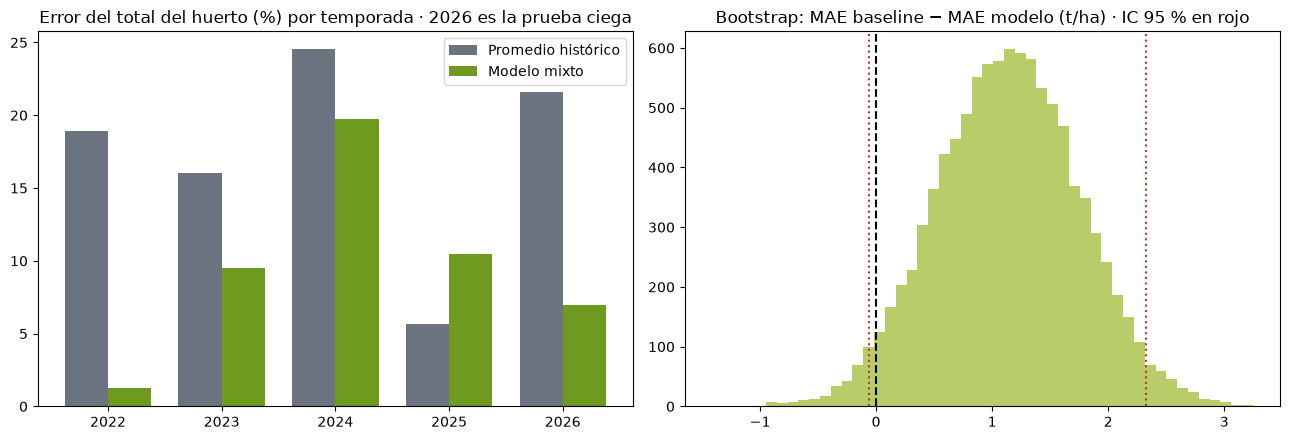

In [10]:
fig, ejes = plt.subplots(1, 2, figsize=(13, 4.5))
anios = t_anio.index.astype(int)
ancho = 0.38
ejes[0].bar(anios - ancho / 2, t_anio['Error_huerto_%|B0 Promedio historico del cuartel'], ancho, color='#6B7280', label='Promedio histórico')
ejes[0].bar(anios + ancho / 2, t_anio['Error_huerto_%|M2 Modelo mixto (cuartel aleatorio)'], ancho, color='#6E9A1F', label='Modelo mixto')
ejes[0].set_title('Error del total del huerto (%) por temporada · 2026 es la prueba ciega')
ejes[0].legend()
ejes[1].hist(difs_boot, bins=50, color='#B9CC6A')
ejes[1].axvline(0, color='black', linestyle='--')
for limite in t_boot['ic95']:
    ejes[1].axvline(limite, color='#B23A2E', linestyle=':')
ejes[1].set_title('Bootstrap: MAE baseline − MAE modelo (t/ha) · IC 95 % en rojo')
plt.tight_layout()
plt.show()

**Lectura.**

1. El modelo le gana al promedio en **4 de 5 años**: justo los años en que el promedio erraba entre 16 y 25 %. Solo pierde en 2025, cuando el promedio ya acertaba (5,7 %).
2. Con toda la historia el baseline da prácticamente lo mismo (16,8 % frente a 17,4 %): la comparación **no favorece** al modelo.
3. Eligiendo solo con 2022–2025 se elige **el mismo** modelo y la misma variante, y en la prueba ciega de 2026 el error del huerto baja de 21,6 % a 7,0 %.
4. La reducción del MAE es de 15,4 % con probabilidad de mejora de 97 %, pero el intervalo de 95 % (−0,1 a 2,3 t/ha) **todavía toca el cero**. Por eso el cuarto criterio de éxito queda pendiente y debe confirmarlo el modelo final.

## 5. Punto de equilibrio: un solo cálculo

El informe de la Entrega 1 reporta **19,1 t/ha**, pero su notebook mostraba **6,9 t/ha**. La diferencia es de costos, no de método de cálculo:

- El notebook usaba solo un costo fijo de $103,2 millones más un costo variable de cosecha por kilo.
- El informe, que es lo que se entregó, suma toda la carta Gantt de labores (incluida la cosecha) y los costos de maquinaria, insumos e indirectos de la ficha ODEPA llevados a valores actuales.

Aquí se deja un solo cálculo, con el criterio del informe. El costo de labores se lee del archivo original; el costo ODEPA por hectárea es el valor publicado en la Entrega 1.

In [11]:
gantt = pd.read_excel(CARPETA_DATOS / 'Kiwis 2026 Gantt planificacion.xlsx', sheet_name='kiwis', header=1)
labores = gantt.loc[gantt['Actividad'].notna(), 'Costo Total'].sum()   # filas de actividades (sin el total)

SUPERFICIE_PLAN_HA = 33.3        # superficie de la carta Gantt
ODEPA_HA = 3_420_000             # maquinaria, insumos e indirectos por ha (ODEPA 2013 x 1,70; Entrega 1)
PRECIO_KG = 450                  # precio de referencia (Entrega 1)

costo_total = labores + ODEPA_HA * SUPERFICIE_PLAN_HA
costo_ha = costo_total / SUPERFICIE_PLAN_HA


def equilibrio(precio):
    return costo_ha / precio / 1000   # t/ha


economia = pd.DataFrame({
    'indicador': ['Labores carta Gantt ($)', 'Maquinaria, insumos e indirectos ODEPA ($)', 'Costo total temporada ($)',
                  'Costo por hectárea ($)', 'Equilibrio a $350/kg (t/ha)', 'Equilibrio a $450/kg (t/ha)',
                  'Equilibrio a $550/kg (t/ha)', 'Escenario pesimista P10 (t/ha)'],
    'valor': [labores, ODEPA_HA * SUPERFICIE_PLAN_HA, costo_total, costo_ha,
              equilibrio(350), equilibrio(PRECIO_KG), equilibrio(550), panel['ton_ha'].quantile(0.10)],
})
economia['valor'] = economia['valor'].map(lambda v: f'{v:,.2f}')
display(economia)

,indicador,valor
0,Labores carta Gantt ($),"173,164,950.00"
1,"Maquinaria, insumos e indirectos ODEPA ($)","113,886,000.00"
2,Costo total temporada ($),"287,050,950.00"
3,Costo por hectárea ($),"8,620,148.65"
4,Equilibrio a $350/kg (t/ha),24.63
5,Equilibrio a $450/kg (t/ha),19.16
6,Equilibrio a $550/kg (t/ha),15.67
7,Escenario pesimista P10 (t/ha),21.91


**Lectura.** El cálculo reproduce el informe de la Entrega 1: labores por $173,2 millones, costo total de $287,1 millones y equilibrio de **19,16 t/ha** a $450/kg, con 24,6 y 15,7 t/ha a $350 y $550. El informe trabajó con el costo redondeado a $287,0 millones y reportó 19,1 t/ha: la diferencia (0,06 t/ha) no cambia ninguna conclusión, y la presentación mantiene 19,1 por coherencia con la Entrega 1. El equilibrio queda bajo el escenario pesimista (P10 = 21,9 t/ha), pero un pronóstico cercano a ese umbral cambia la decisión: por eso el modelo debe entregar **intervalos** y no solo un valor puntual.

Para la entrega final queda reemplazar el costo ODEPA por costos reales del huerto y separar los costos que varían con los kilos cosechados.

## 6. Salidas para la presentación

| Archivo en `salidas/` | Se usa en |
|---|---|
| `panel_integrado.csv` | Base de todo el análisis |
| `scatter_ene.json` | Diapositiva 3: dispersión canopia vs rendimiento |
| `resultados_validacion.csv` | Diapositivas 6 y 11: comparación de modelos y fecha de corte |
| `predicciones_*.csv` | Predicciones fuera de muestra por modelo y variante |
| `robustez.json` | Diapositivas 8 y 10: criterios de éxito, resultado por año y prueba ciega |

La presentación se reconstruye con `node build_deck.js` en la carpeta `presentacion`, después de ejecutar este notebook.

In [12]:
for archivo in sorted(CARPETA_SALIDA.iterdir()):
    print(f'{archivo.name:40s} {archivo.stat().st_size:>9,d} bytes')

panel_integrado.csv                         28,771 bytes
predicciones_cnp_acum_dic.csv               24,504 bytes
predicciones_cnp_acum_ene.csv               24,522 bytes
predicciones_cnp_acum_feb.csv               24,524 bytes
predicciones_cnp_media_completa.csv         24,525 bytes
predicciones_cnp_media_ene.csv              24,507 bytes
resultados_validacion.csv                    1,956 bytes
robustez.json                                5,665 bytes
scatter_ene.json                             1,159 bytes
